# **Paths and connectivity**

This notebook illustrates the following concepts using Zachary's Karate Club network:

1. Path, distance, average shortest path length, and diameter  
2. Eccentricity, center, and periphery  
3. Connectivity and induced subgraphs  
4. Connected, weakly connected, and strongly connected components  
5. Giant component  
6. Bridges (cut edges)  
7. Cut sets, node/edge connectivity, and minimum cuts  

### Notes

- NetworkX's Karate Club graph contains an edge attribute called `weight`. This notebook uses unweighted shortest paths and connectivity measures.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display
from networkx.algorithms.connectivity import (
    edge_connectivity,
    minimum_edge_cut,
    minimum_node_cut,
    node_connectivity,
)

SOURCE, TARGET = 0, 33
DEGREE_THRESHOLD = 4

print("NetworkX version:", nx.__version__)

NetworkX version: 3.6.1


## 0. Load the dataset

In Zachary's Karate Club nodes represent club members and edges represent observed social ties. Therefore, it is an undirected network.
For directed examples, we create a symmetric directed version, `DG`, by replacing every undirected edge with two directed edges. Therefore, strong and weak connectivity coincide here whenever the original graph is connected.

In [2]:
G = nx.karate_club_graph()
DG = G.to_directed()  # each undirected edge becomes u -> v and v -> u

n = G.number_of_nodes()
m = G.number_of_edges()

# Fixed layout so that all figures use exactly the same geometry.
pos = nx.spring_layout(G, seed=42, weight=None)

print("Zachary's Karate Club")
print("======================")
print(f"Nodes: {n}")
print(f"Edges: {m}")
print(f"Connected: {nx.is_connected(G)}")

Zachary's Karate Club
Nodes: 34
Edges: 78
Connected: True


### Utilities

The helper below keeps the visual style consistent across the notebook.

In [3]:
def draw_graph(
    graph,
    title,
    *,
    node_colors=None,
    node_sizes=None,
    edge_colors=None,
    edge_widths=None,
    labels=True,
):
    """Draw a graph using the fixed Karate Club layout."""
    nodes = list(graph.nodes())
    edges = list(graph.edges())

    plt.figure(figsize=(9, 6))
    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=edges,
        alpha=0.35,
        edge_color=edge_colors if edge_colors is not None else "gray",
        width=edge_widths if edge_widths is not None else 1.2,
        arrows=graph.is_directed(),
    )

    nx.draw_networkx_nodes(
        graph,
        pos,
        nodelist=nodes,
        node_color=node_colors if node_colors is not None else "lightgray",
        node_size=node_sizes if node_sizes is not None else 520,
        edgecolors="black",
        linewidths=0.7,
    )

    if labels:
        nx.draw_networkx_labels(graph, pos, font_size=8)

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

Optional: Making the directed graph asymetric by removing edges

In [4]:
# DG_asymmetric = DG.copy()

# # Remove all directions from the "Mr. Hi" faction
# # toward the "Officer" faction.
# edges_to_remove = [
#     (u, v)
#     for u, v in DG_asymmetric.edges()
#     if G.nodes[u]["club"] == "Mr. Hi"
#     and G.nodes[v]["club"] == "Officer"
# ]

# print("Directed edges to remove:")
# print(edges_to_remove)

# DG_asymmetric.remove_edges_from(edges_to_remove)

# print("\nWeakly connected:",
#       nx.is_weakly_connected(DG_asymmetric))

# print("Strongly connected:",
#       nx.is_strongly_connected(DG_asymmetric))

# scc = list(nx.strongly_connected_components(DG_asymmetric))

# print("\nNumber of strongly connected components:", len(scc))
# print("SCC sizes:", sorted([len(c) for c in scc], reverse=True))

# DG = DG_asymmetric.copy()

# club_colors = [
#     "skyblue" if G.nodes[n]["club"] == "Mr. Hi"
#     else "lightcoral"
#     for n in DG_asymmetric.nodes()
# ]

# draw_graph(
#     DG_asymmetric,
#     "Directed Karate Club Graph: one-way communication between factions",
#     node_colors=club_colors,
# )

## 1. Path and distance

A **path** is a sequence of vertices connected by edges. Its length is the number of edges traversed.

For two nodes $u$ and $v$, the *shortest-path distance* $d(u,v)$ is the length of a shortest path between them.

Two network-level summaries are:

- *Average shortest path length:* the average of shortest-path distances over all pairs of nodes.
- *Diameter:* the largest shortest-path distance between any two nodes.

**Question:** How many steps separate nodes 0 and 33, and how does that compare with distances across the whole network?

Shortest path from 0 to 33: [0, 8, 33]
Shortest path length: 2
Average shortest path length: 2.408
Diameter: 5


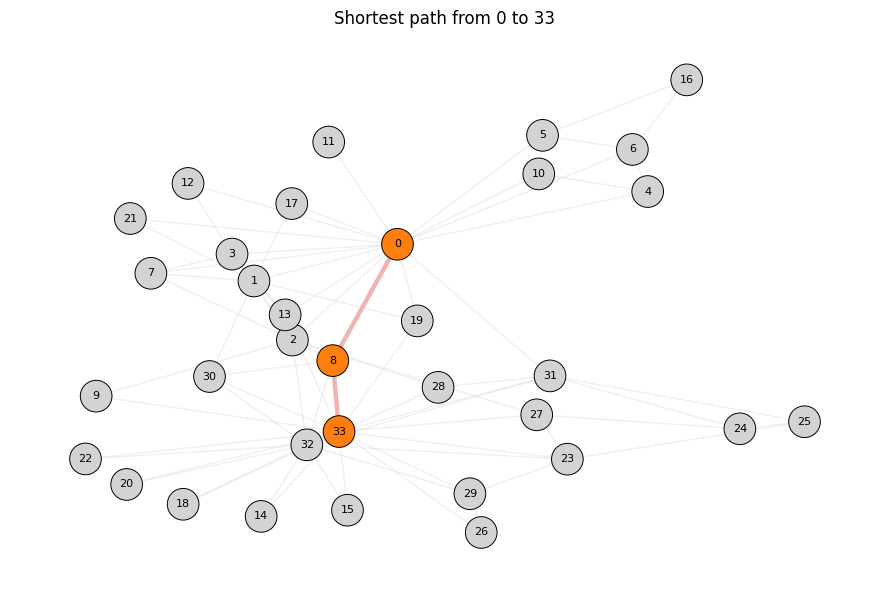

In [5]:
source, target = SOURCE, TARGET

shortest_path = nx.shortest_path(G, source=source, target=target)
shortest_distance = nx.shortest_path_length(G, source=source, target=target)
avg_spl = nx.average_shortest_path_length(G)
diameter = nx.diameter(G)

print(f"Shortest path from {source} to {target}: {shortest_path}")
print(f"Shortest path length: {shortest_distance}")
print(f"Average shortest path length: {avg_spl:.3f}")
print(f"Diameter: {diameter}")

path_edges = set(zip(shortest_path[:-1], shortest_path[1:]))
path_edges |= {(v, u) for u, v in path_edges}

edge_colors = ["tab:red" if (u, v) in path_edges else "lightgray" for u, v in G.edges()]
edge_widths = [3.2 if (u, v) in path_edges else 1.0 for u, v in G.edges()]
node_colors = ["tab:orange" if node in shortest_path else "lightgray" for node in G.nodes()]

draw_graph(
    G,
    f"Shortest path from {source} to {target}",
    node_colors=node_colors,
    edge_colors=edge_colors,
    edge_widths=edge_widths,
)

## 2. Eccentricity, center, and periphery

The *eccentricity* of a node is its maximum shortest-path distance to any other node:

$$e(v)=\max_u d(v,u).$$

- The *center* contains the node(s) with minimum eccentricity.
- The *periphery* contains the node(s) whose eccentricity equals the graph diameter.

**Question:** Which club members are structurally central in the distance sense, and which are furthest from the rest of the network?

Eccentricity of node 0: 3
Radius (minimum eccentricity): 3
Diameter (maximum eccentricity): 5
Center nodes: [0, 1, 2, 3, 8, 13, 19, 31]
Periphery nodes: [14, 15, 16, 18, 20, 22, 23, 26, 29]


,node,eccentricity,role
0,0,3,center
1,1,3,center
2,2,3,center
3,3,3,center
8,8,3,center
13,13,3,center
19,19,3,center
31,31,3,center
4,4,4,other
5,5,4,other


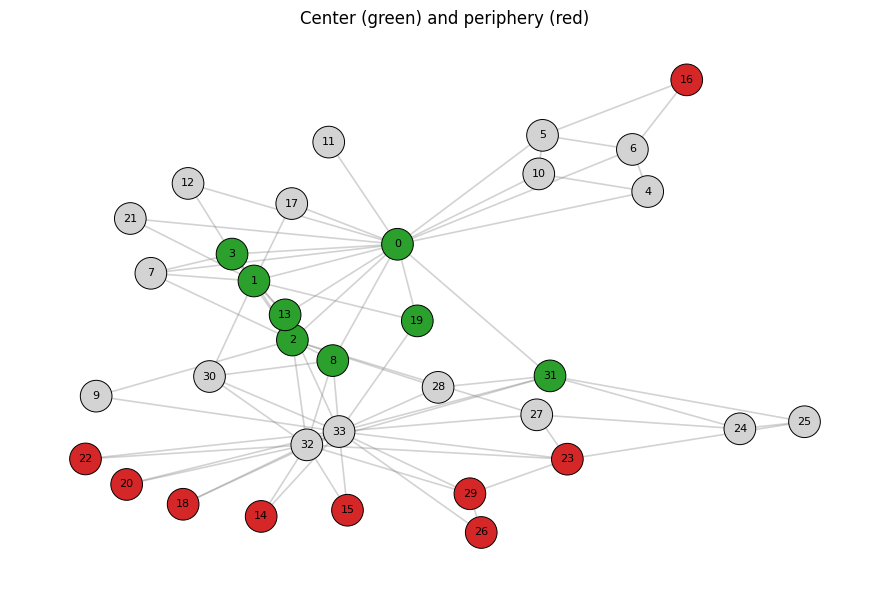

In [6]:
eccentricity = nx.eccentricity(G)
center_nodes = nx.center(G)
periphery_nodes = nx.periphery(G)

print(f"Eccentricity of node 0: {eccentricity[0]}")
print(f"Radius (minimum eccentricity): {nx.radius(G)}")
print(f"Diameter (maximum eccentricity): {nx.diameter(G)}")
print(f"Center nodes: {center_nodes}")
print(f"Periphery nodes: {periphery_nodes}")

summary = pd.DataFrame(
    {
        "node": list(G.nodes()),
        "eccentricity": [eccentricity[node] for node in G.nodes()],
        "role": [
            "center" if node in center_nodes else
            "periphery" if node in periphery_nodes else
            "other"
            for node in G.nodes()
        ],
    }
).sort_values(["eccentricity", "node"])

display(summary)

node_colors = [
    "tab:green" if node in center_nodes else
    "tab:red" if node in periphery_nodes else
    "lightgray"
    for node in G.nodes()
]

draw_graph(
    G,
    "Center (green) and periphery (red)",
    node_colors=node_colors,
)

## 3. Connectivity and subgraphs

An undirected graph is *connected* if there is a path between every pair of vertices.

For directed graphs:

- *Strongly connected:* every node can reach every other node while respecting edge directions.
- *Weakly connected:* the graph becomes connected after ignoring edge directions.

A *subgraph* contains a subset of the original graph's nodes and edges. Here we form an *induced subgraph* containing nodes whose degree in the original graph is at least 4.

Is G connected (undirected)? True
Is DG strongly connected? True
Is DG weakly connected? True

Induced subgraph with degree >= 4
Nodes: 16
Edges: 39
Connected: True
Nodes kept: [0, 1, 2, 3, 5, 6, 7, 8, 13, 23, 27, 29, 30, 31, 32, 33]


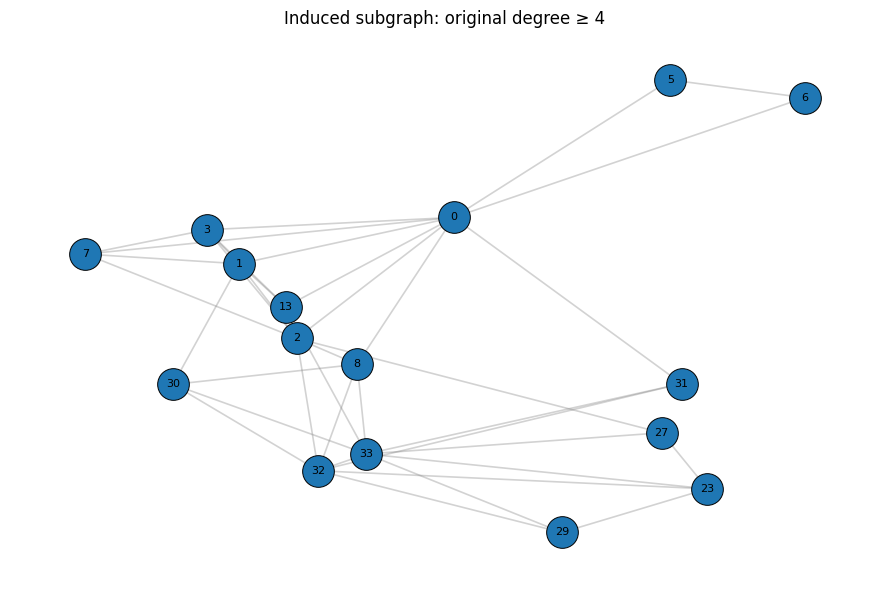

In [7]:
print(f"Is G connected (undirected)? {nx.is_connected(G)}")
print(f"Is DG strongly connected? {nx.is_strongly_connected(DG)}")
print(f"Is DG weakly connected? {nx.is_weakly_connected(DG)}")

high_degree = [node for node, degree in G.degree if degree >= DEGREE_THRESHOLD]
H = G.subgraph(high_degree).copy()

print()
print(f"Induced subgraph with degree >= {DEGREE_THRESHOLD}")
print(f"Nodes: {H.number_of_nodes()}")
print(f"Edges: {H.number_of_edges()}")
print(f"Connected: {nx.is_connected(H) if H.number_of_nodes() > 0 else 'N/A'}")
print(f"Nodes kept: {sorted(H.nodes())}")

draw_graph(
    H,
    f"Induced subgraph: original degree ≥ {DEGREE_THRESHOLD}",
    node_colors="tab:blue",
)

### A note on the directed version

Because `DG = G.to_directed()` adds both $u	\to v$ and $v	\to u$ for every undirected edge, it does *not* create one-way reachability. It is useful for demonstrating the NetworkX API, but a genuinely directed dataset can have different strong and weak connectivity.

## 4. Bridges (cut edges)

A *bridge* is an edge whose removal increases the number of connected components. Bridges are therefore single-edge points of structural vulnerability.

**Question:** Does the Karate Club network contain any edge whose removal disconnects the graph?

Number of bridges in G: 1
Bridges: [(0, 11)]


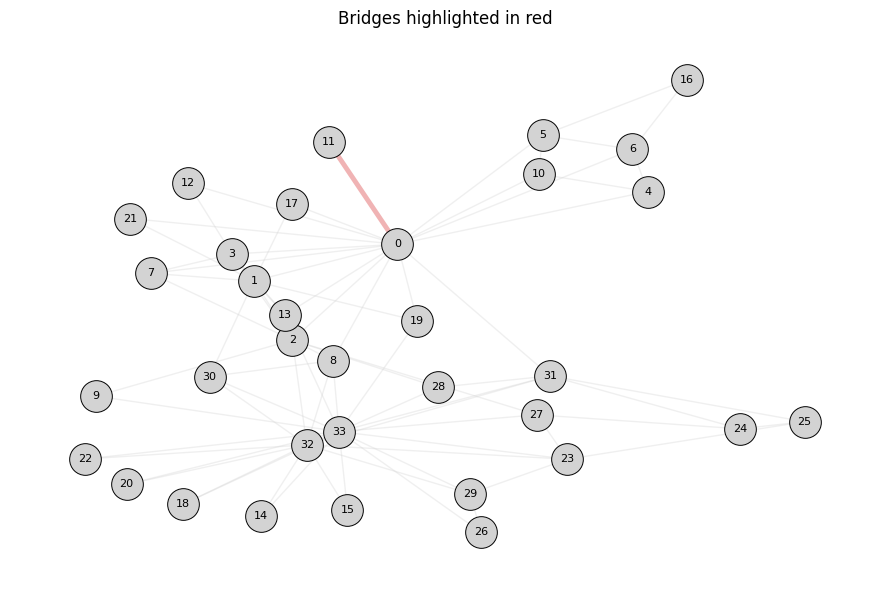

In [8]:
bridges = list(nx.bridges(G))

print(f"Number of bridges in G: {len(bridges)}")
print(f"Bridges: {bridges}")

bridge_set = set(bridges) | {(v, u) for u, v in bridges}
edge_colors = ["tab:red" if (u, v) in bridge_set else "lightgray" for u, v in G.edges()]
edge_widths = [3.5 if (u, v) in bridge_set else 1.0 for u, v in G.edges()]

draw_graph(
    G,
    "Bridges highlighted in red",
    edge_colors=edge_colors,
    edge_widths=edge_widths,
)

## 5. Components

A *connected component* is a maximal connected subgraph of an undirected graph.

In directed graphs:

- A *strongly connected component (SCC)* is a maximal group of nodes that are mutually reachable while respecting directions.
- A *weakly connected component (WCC)* is a maximal group that is connected after edge directions are ignored.

**Question:** Is the Karate Club graph fragmented into separate pieces?

In [9]:
connected_components = list(nx.connected_components(G))
strong_components = list(nx.strongly_connected_components(DG))
weak_components = list(nx.weakly_connected_components(DG))

print(f"Connected components in G: {len(connected_components)}")
print("Connected-component sizes:", sorted((len(c) for c in connected_components), reverse=True))
print()
print(f"Strongly connected components in DG: {len(strong_components)}")
print("SCC sizes:", sorted((len(c) for c in strong_components), reverse=True))
print(f"Weakly connected components in DG: {len(weak_components)}")
print("WCC sizes:", sorted((len(c) for c in weak_components), reverse=True))

Connected components in G: 1
Connected-component sizes: [34]

Strongly connected components in DG: 1
SCC sizes: [34]
Weakly connected components in DG: 1
WCC sizes: [34]


### Making fragmentation visible

The original Karate Club graph has one connected component, so component coloring would show only one group. To visualize what components *look like*, remove the graph's bridge edge and recompute the components.

Removed bridge: (0, 11)
Number of components after removal: 2
Component sizes: [33, 1]


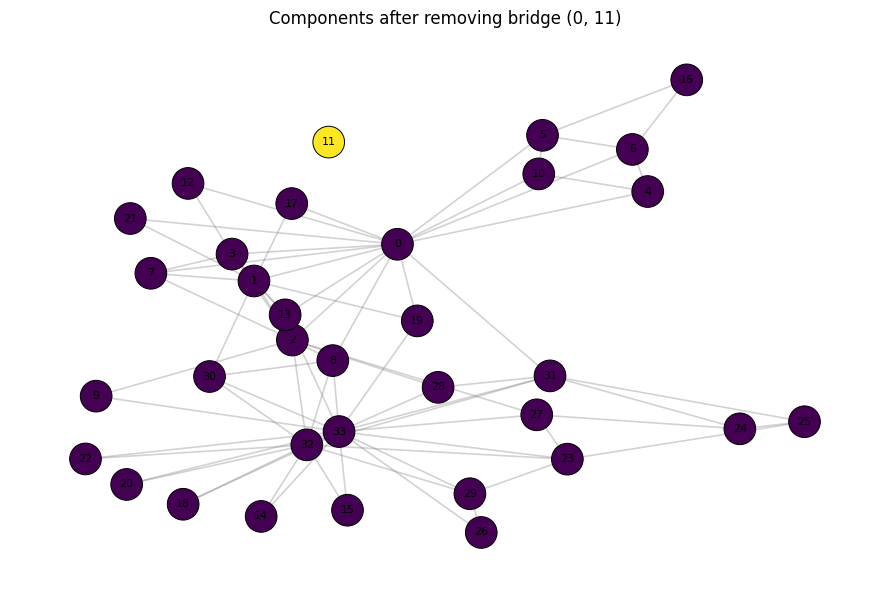

In [10]:
bridges_for_demo = list(nx.bridges(G))
G_split = G.copy()

if bridges_for_demo:
    demo_bridge = bridges_for_demo[0]
    G_split.remove_edge(*demo_bridge)
    split_components = list(nx.connected_components(G_split))

    print(f"Removed bridge: {demo_bridge}")
    print(f"Number of components after removal: {len(split_components)}")
    print("Component sizes:", sorted((len(c) for c in split_components), reverse=True))

    component_id = {
        node: i
        for i, component in enumerate(split_components)
        for node in component
    }
    node_colors = [component_id[node] for node in G_split.nodes()]
    draw_graph(
        G_split,
        f"Components after removing bridge {demo_bridge}",
        node_colors=node_colors,
    )
else:
    print("No bridge is available for this demonstration.")

## 6. Giant component

The *giant component* is the largest connected component of a network. In empirical networks it is often useful to report both its size and the fraction of all nodes it contains.

For a connected graph, the giant component is simply the entire graph.

In [11]:
components = list(nx.connected_components(G))
giant_nodes = max(components, key=len)
G_giant = G.subgraph(giant_nodes).copy()
giant_fraction = G_giant.number_of_nodes() / G.number_of_nodes()

print(f"Giant component size: {G_giant.number_of_nodes()}")
print(f"Fraction of nodes in giant component: {giant_fraction:.3f}")

# Compare with the intentionally split graph from the previous section.
if 'G_split' in globals() and nx.number_connected_components(G_split) > 1:
    split_giant_nodes = max(nx.connected_components(G_split), key=len)
    split_fraction = len(split_giant_nodes) / G_split.number_of_nodes()
    print()
    print("After the bridge-removal demonstration:")
    print(f"Giant component size: {len(split_giant_nodes)}")
    print(f"Fraction of nodes in giant component: {split_fraction:.3f}")

Giant component size: 34
Fraction of nodes in giant component: 1.000

After the bridge-removal demonstration:
Giant component size: 33
Fraction of nodes in giant component: 0.971


## 7. Cut sets and connectivity

A *cut set* is a set of nodes or edges whose removal disconnects the graph (or, for a specified pair, separates one node from the other).

Two global robustness measures are:

- *Node connectivity* $\kappa(G)$: minimum number of nodes whose removal disconnects the graph.
- *Edge connectivity* $\lambda(G)$: minimum number of edges whose removal disconnects the graph.

We also compute *pairwise minimum cuts* between nodes 0 and 33. Pairwise cuts can be larger than the graph-wide connectivity because the easiest place to disconnect the graph may be elsewhere.

In [12]:
kappa = node_connectivity(G)
lambda_ = edge_connectivity(G)

min_node_cut_uv = minimum_node_cut(G, s=SOURCE, t=TARGET)
min_edge_cut_uv = minimum_edge_cut(G, s=SOURCE, t=TARGET)

print(f"Global node connectivity κ(G): {kappa}")
print(f"Global edge connectivity λ(G): {lambda_}")
print()
print(
    f"Minimum node cut between {SOURCE} and {TARGET}: "
    f"{sorted(min_node_cut_uv)} (size: {len(min_node_cut_uv)})"
)
print(
    f"Minimum edge cut between {SOURCE} and {TARGET}: "
    f"{sorted(min_edge_cut_uv)} (size: {len(min_edge_cut_uv)})"
)

Global node connectivity κ(G): 1
Global edge connectivity λ(G): 1

Minimum node cut between 0 and 33: [2, 8, 13, 19, 30, 31] (size: 6)
Minimum edge cut between 0 and 33: [(0, 8), (0, 31), (1, 30), (2, 8), (2, 27), (2, 28), (2, 32), (9, 33), (13, 33), (19, 33)] (size: 10)


### Visualize the pairwise minimum node cut

The highlighted cut nodes are one minimum set whose removal separates node 0 from node 33.

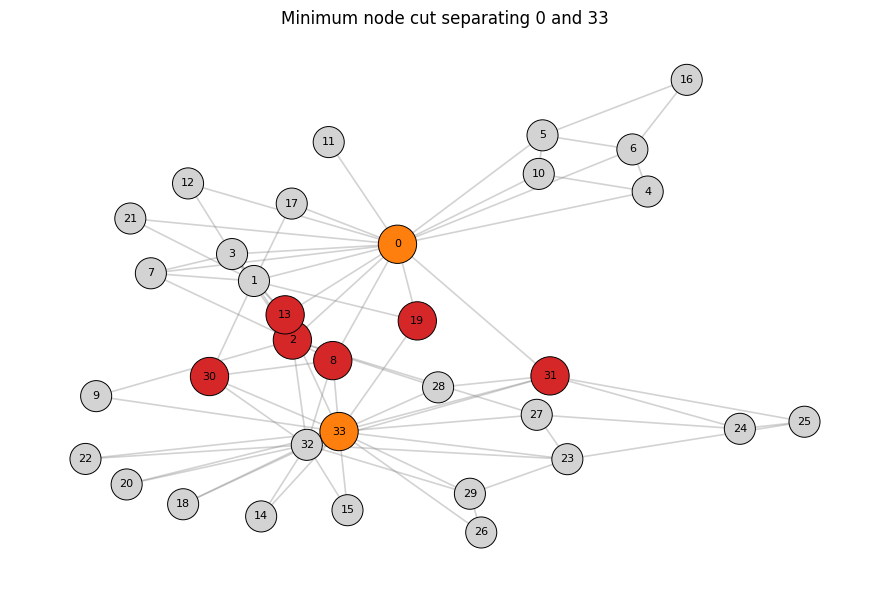

In [13]:
node_colors = [
    "tab:red" if node in min_node_cut_uv else
    "tab:orange" if node in {SOURCE, TARGET} else
    "lightgray"
    for node in G.nodes()
]
node_sizes = [760 if node in min_node_cut_uv or node in {SOURCE, TARGET} else 500 for node in G.nodes()]

draw_graph(
    G,
    f"Minimum node cut separating {SOURCE} and {TARGET}",
    node_colors=node_colors,
    node_sizes=node_sizes,
)

### Verify the cut

A useful habit is to verify the definition computationally: remove the cut set and check whether the selected endpoints are still connected.

In [14]:
G_without_node_cut = G.copy()
G_without_node_cut.remove_nodes_from(min_node_cut_uv)

G_without_edge_cut = G.copy()
G_without_edge_cut.remove_edges_from(min_edge_cut_uv)

print(
    f"Path from {SOURCE} to {TARGET} after removing the minimum node cut? ",
    nx.has_path(G_without_node_cut, SOURCE, TARGET),
)
print(
    f"Path from {SOURCE} to {TARGET} after removing the minimum edge cut? ",
    nx.has_path(G_without_edge_cut, SOURCE, TARGET),
)

Path from 0 to 33 after removing the minimum node cut?  False
Path from 0 to 33 after removing the minimum edge cut?  False


## 8. Summary table

The table below gathers the main graph-level quantities from this lab in one place.

In [15]:
summary_table = pd.DataFrame(
    {
        "measure": [
            "nodes",
            "edges",
            "average shortest path length",
            "diameter",
            "radius",
            "number of connected components",
            "giant-component fraction",
            "number of bridges",
            "node connectivity",
            "edge connectivity",
        ],
        "value": [
            G.number_of_nodes(),
            G.number_of_edges(),
            nx.average_shortest_path_length(G),
            nx.diameter(G),
            nx.radius(G),
            nx.number_connected_components(G),
            giant_fraction,
            len(bridges),
            kappa,
            lambda_,
        ],
    }
)

display(summary_table)

,measure,value
0,nodes,34.0000
1,edges,78.0000
2,average shortest path length,2.4082
3,diameter,5.0000
4,radius,3.0000
5,number of connected components,1.0000
6,giant-component fraction,1.0000
7,number of bridges,1.0000
8,node connectivity,1.0000
9,edge connectivity,1.0000


## 9. Discussion

1. Why can global node/edge connectivity be smaller than the minimum cut separating a particular pair of nodes?
2. In a communication or transportation network, which would concern you more: low node connectivity or low edge connectivity? Explain the failure scenario you have in mind.

## 10. Role of the edge weights


Original directed graph: 34 nodes, 156 edges
Thresholded graph (weight >= 3): 34 nodes, 96 edges


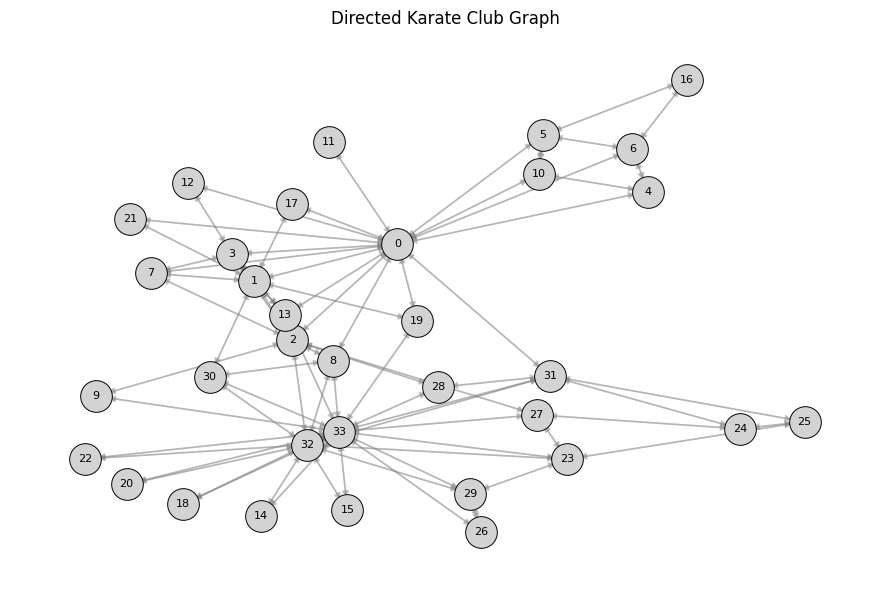

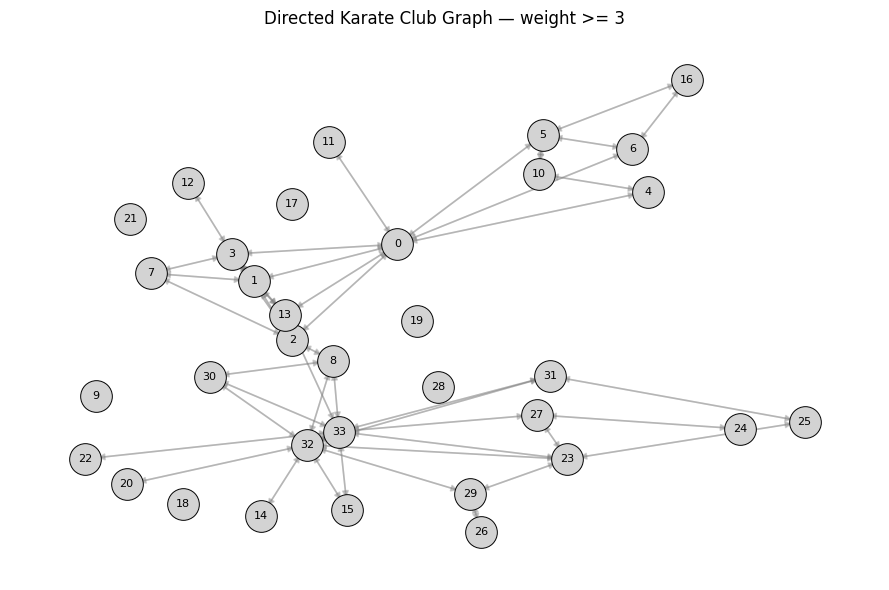

In [16]:
def threshold_directed_graph(DG, min_weight=3):
    """
    Return a copy of DG containing only edges whose weight
    is greater than or equal to min_weight.

    All original nodes are kept, so nodes that lose all their
    edges remain visible as isolated nodes.
    """
    DG_threshold = nx.DiGraph()

    # Keep all nodes and their attributes
    DG_threshold.add_nodes_from(DG.nodes(data=True))

    # Keep only sufficiently strong edges
    for u, v, data in DG.edges(data=True):
        if data.get("weight", 1) >= min_weight:
            DG_threshold.add_edge(u, v, **data)

    return DG_threshold


WEIGHT_THRESHOLD = 3
DG_threshold = threshold_directed_graph(DG, WEIGHT_THRESHOLD)

print(f"Original directed graph: {DG.number_of_nodes()} nodes, "
      f"{DG.number_of_edges()} edges")

print(f"Thresholded graph (weight >= {WEIGHT_THRESHOLD}): "
      f"{DG_threshold.number_of_nodes()} nodes, "
      f"{DG_threshold.number_of_edges()} edges")

draw_graph(
    DG,
    f"Directed Karate Club Graph"
)

draw_graph(
    DG_threshold,
    f"Directed Karate Club Graph — weight >= {WEIGHT_THRESHOLD}"
)